<table border=0 width="100%"><tr><td><p align="left"><img src="..\img\logo.png" align="left" width=300></p></td><td><font size=3><B>market movement prediciton - random forest(Haichao Zheng)</B></font></td></tr></table>

# 授课内容
* 餐馆评论朴素贝叶斯模型
* 评论情感分类模型集成
* 生成每天的情感和意见分歧
* 合并市场数据、百度指数与情感指数
* 数据可视化与探索分析
* 决策树和随机森林
* 应用随机森林提前一天预测价格涨跌
* 个人项目
* 课后练习题

# 餐馆评论情感预测朴素贝叶斯模型



# 评论情感分类模型集成

## 模型的集成

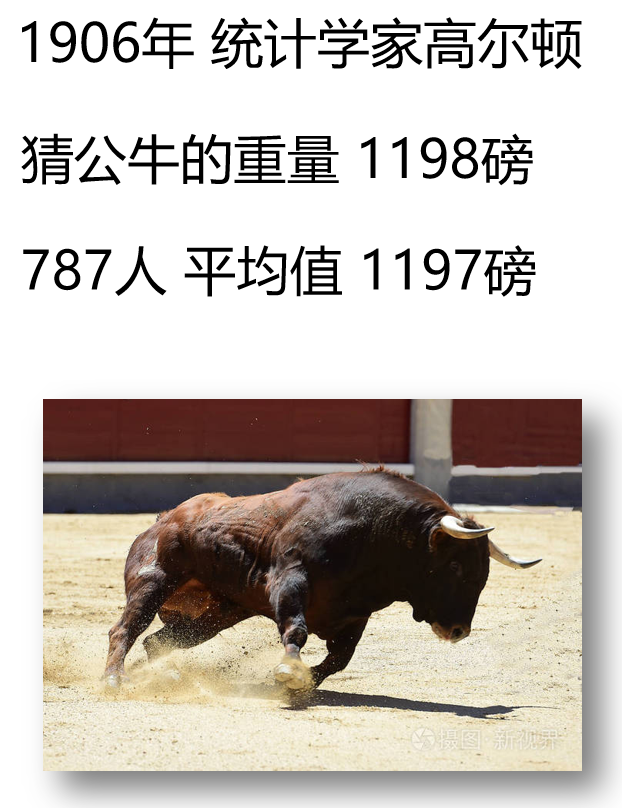

更多蜂群智慧的例子

- honeybee democracy

Voting Classifiers

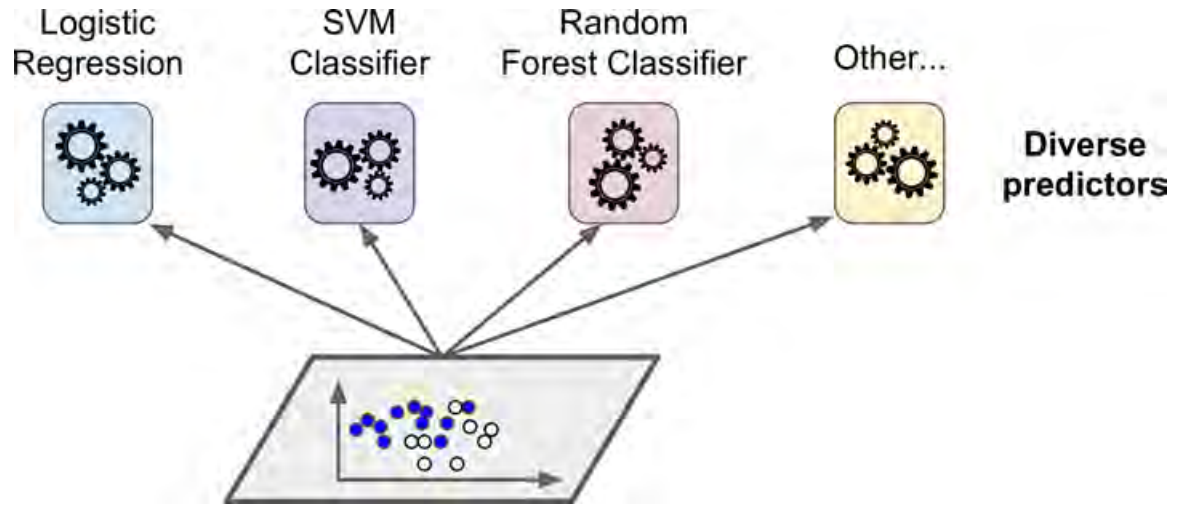

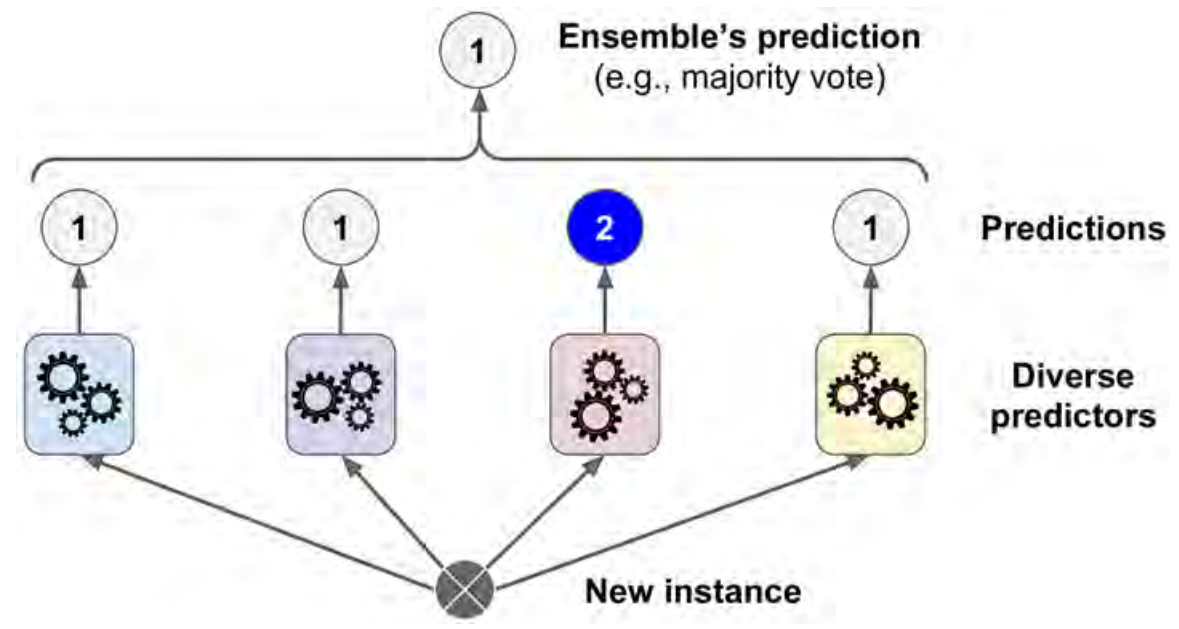

Somewhat surprisingly, this voting classifier often achieves a higher accuracy than the
best classifier in the ensemble. In fact, even if each classifier is a weak learner (mean‐
ing it does only slightly better than random guessing), the ensemble can still be a
strong learner (achieving high accuracy), provided there are a sufficient number of
weak learners and they are sufficiently diverse.

One way to get diverse classifiers
is to train them using very different algorithms.

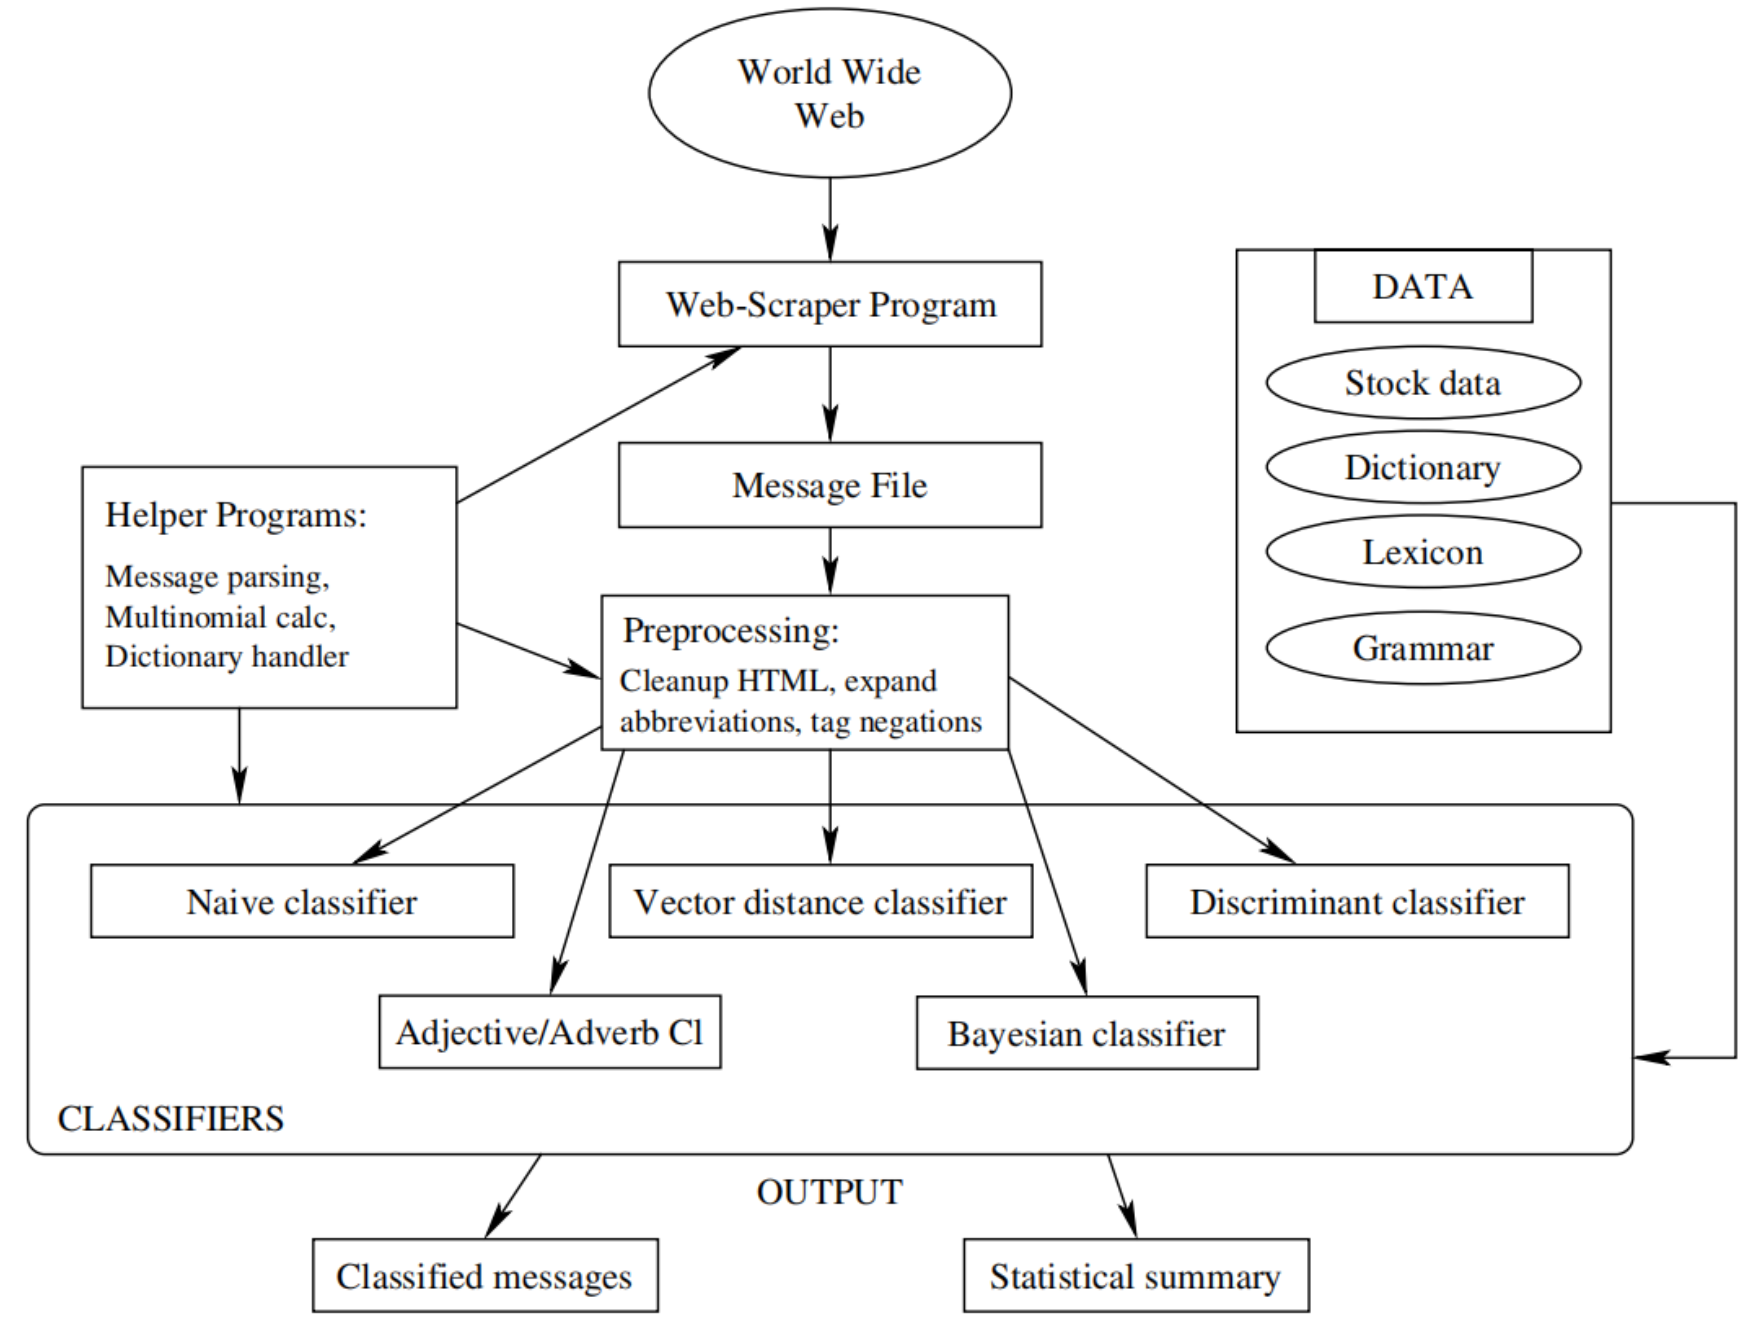

## 课堂练习: ensemble sentiment analysis results from three approaches

In [1]:
# 导入数据
import pandas as pd
cols = ['modified_date', 'comment', 'cutted_comment', 'sentiment_naive',
       'sentiment_discriminate', 'sentiment_MultinomialNB_clf']
comments = pd.read_csv("cleaned_300251_comments_sentiment.csv",
                      index_col=False, 
                      parse_dates = ["modified_date"],
                       usecols = cols)
comments.head(2)

,modified_date,comment,cutted_comment,sentiment_naive,sentiment_discriminate,sentiment_MultinomialNB_clf
0,2011-07-15,"高泡沬发行新股,破坏了上市公司融资,另打新的热闹气氛散去近期打新虽然有一些利润,但打新股民没...","高泡 沬 发行 新股 , 破坏 了 上市公司 融资 , 另 打 新 的 热闹 气氛 散 去 ...",-1,-1,-1
1,2011-07-15,中吧中新股发大财,中 吧 中 新股 发大财,1,1,-1


In [2]:
# 三种分类器进行投票
vote = comments.sentiment_naive + comments.sentiment_discriminate + comments.sentiment_MultinomialNB_clf
comments["ensemble_sentiment"] = vote.apply(lambda x: 1 if x>0 else -1)

In [3]:
comments.head(50)

,modified_date,comment,cutted_comment,sentiment_naive,sentiment_discriminate,sentiment_MultinomialNB_clf,ensemble_sentiment
0,2011-07-15,"高泡沬发行新股,破坏了上市公司融资,另打新的热闹气氛散去近期打新虽然有一些利润,但打新股民没...","高泡 沬 发行 新股 , 破坏 了 上市公司 融资 , 另 打 新 的 热闹 气氛 散 去 ...",-1,-1,-1,-1
1,2011-07-15,中吧中新股发大财,中 吧 中 新股 发大财,1,1,-1,1
2,2011-07-15,33,33,-1,-1,-1,-1
3,2011-07-15,发行价30块立帖为证,发行价 30 块 立帖 为证,-1,-1,-1,-1
4,2011-07-15,发行价26元市盈率24倍,发行价 26 元 市盈率 24 倍,-1,-1,-1,-1
5,2011-07-15,应收账款与日俱增四川依米康过分依赖大客户应收账款与日俱增四川依米康过分依赖大客户,应收 账款 与日俱增 四川 依米康 过分 依赖 大 客户 应收 账款 与日俱增 四川 依米康...,-1,-1,-1,-1
6,2011-07-15,8888888888,8888888888,-1,-1,1,-1
7,2011-07-15,好股，拿住！百元股！请记住我的话！,好股 ， 拿住 ！ 百元 股 ！ 请 记住 我 的话 ！,1,1,-1,1
8,2011-07-16,好股！上香求中！保佑我中一签！,好股 ！ 上香求 中 ！ 保佑 我 中 一签 ！,1,1,-1,1
9,2011-07-18,光线传媒股发行后总股本1.096亿 继华谊兄弟、华策影视之后，又一影视传媒公司——光线传媒...,光线传媒 股 发行 后 总 股本 1.096 亿 继 华谊 兄弟 、 华策 影视 之...,1,1,1,1


In [4]:
# 查看正面评论与负面评论的分布
comments["ensemble_sentiment"].value_counts()

-1    84338
 1    39996
Name: ensemble_sentiment, dtype: int64

In [5]:
comments["sentiment_naive"].value_counts()

-1    85982
 1    38352
Name: sentiment_naive, dtype: int64

In [6]:
comments["sentiment_MultinomialNB_clf"].value_counts()

-1    83658
 1    40676
Name: sentiment_MultinomialNB_clf, dtype: int64

In [7]:
comments["sentiment_discriminate"].value_counts()

-1    79421
 1    44913
Name: sentiment_discriminate, dtype: int64

# 生成每天的情感和意见分歧

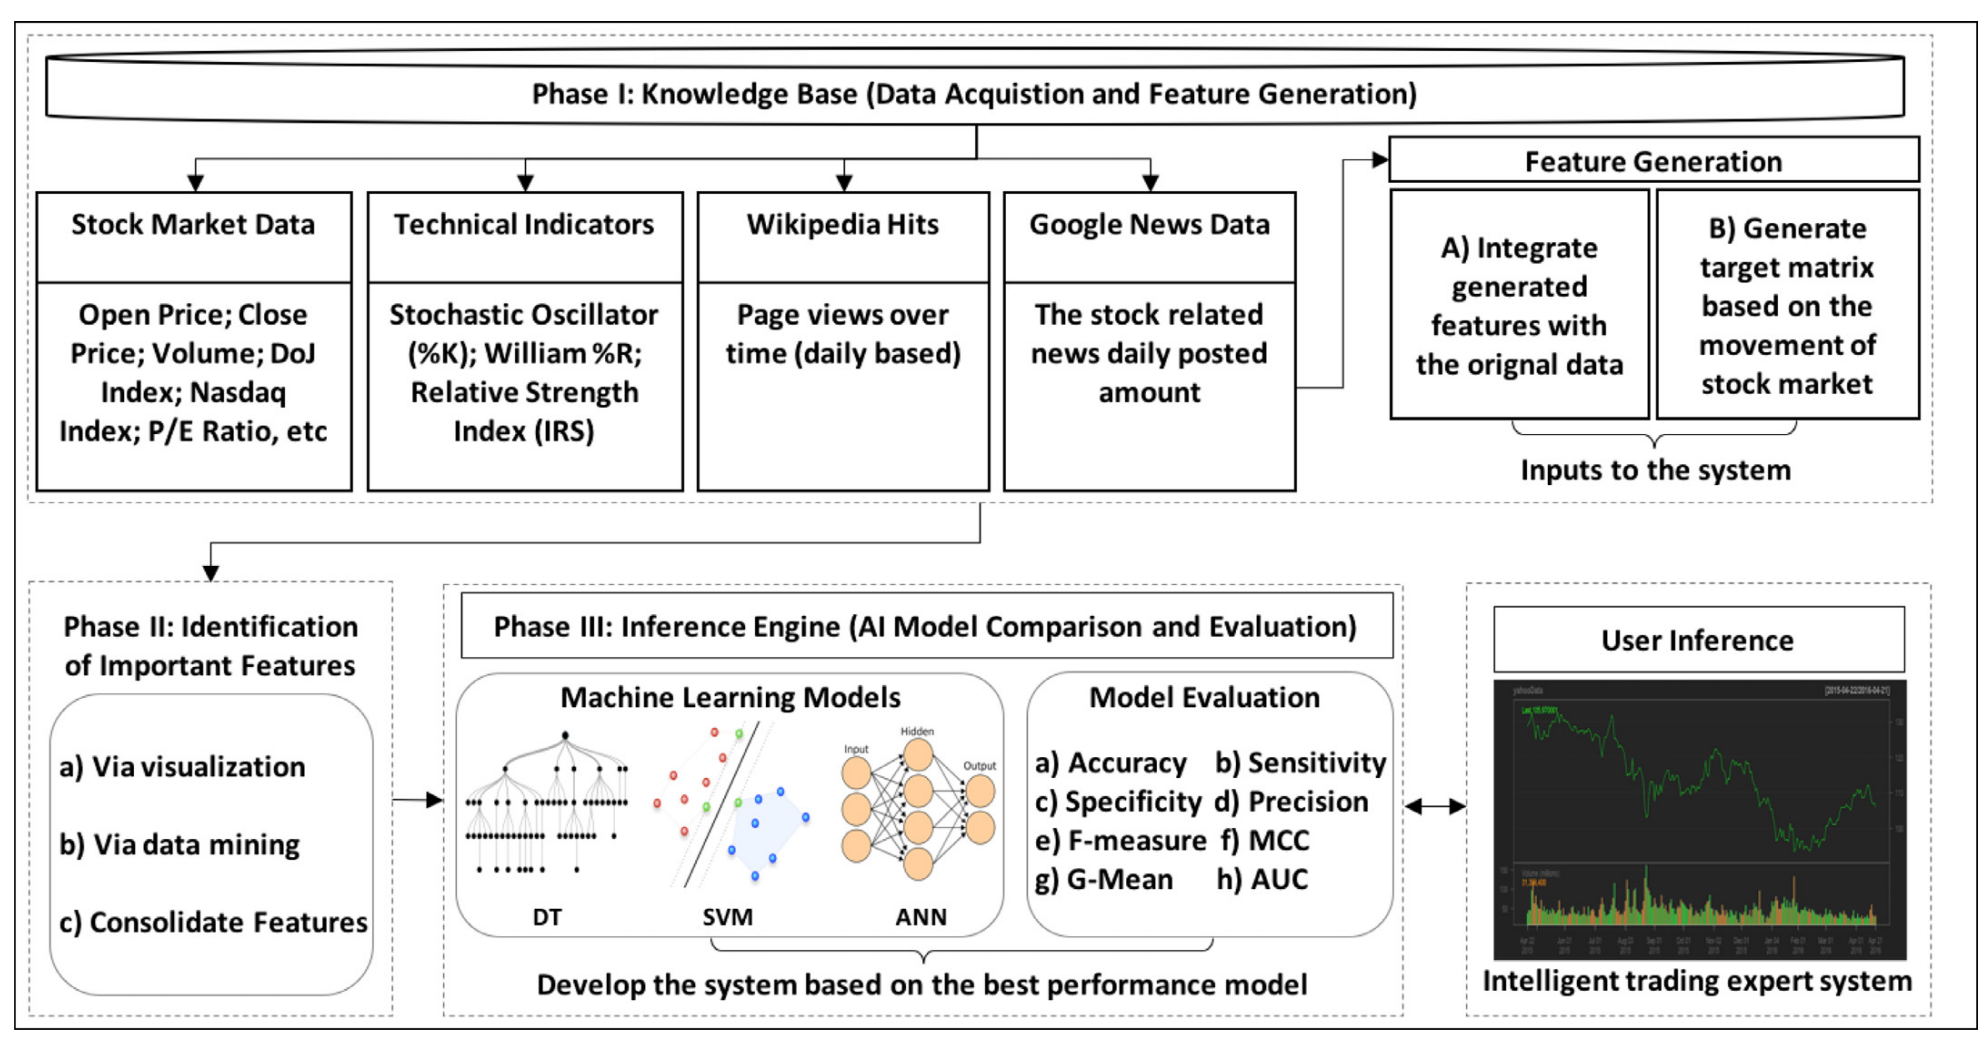

目前，我们计算了每条股评的情感打分。后续我们做股价涨跌预测是以天为单位的。因此，我们要为后续建模汇总每天的特征，例如每天的情感分数、意见分歧指数。

## 计算每天的情感分值（get the daily sentiments scores）

第一步：读取评论，这里只读取日期和情感打分，此后我们不再关注评论文本

In [8]:
comments.columns

Index(['modified_date', 'comment', 'cutted_comment', 'sentiment_naive',
       'sentiment_discriminate', 'sentiment_MultinomialNB_clf',
       'ensemble_sentiment'],
      dtype='object')

In [9]:
# 删除评论的文本数据
comments.drop(['comment', 'cutted_comment'],axis=1,inplace=True)

In [10]:
comments.head(2)

,modified_date,sentiment_naive,sentiment_discriminate,sentiment_MultinomialNB_clf,ensemble_sentiment
0,2011-07-15,-1,-1,-1,-1
1,2011-07-15,1,1,-1,1


第二步：判断一条评论是正面评论还是负面评论，生成两列positive和negative

In [11]:
# 这里我们使用ensemble_sentiment（即投票所得的情感分数）
# 后续大家也可以用其他情感标签做实验（sentiment_naive，sentiment_discriminate，sentiment_MultinomialNB_clf）的效果
sentiment_label = "ensemble_sentiment"

comments["positive"] = comments[sentiment_label].apply(lambda x: 1 if x==1 else 0)
comments["negative"] = comments[sentiment_label].apply(lambda x: 1 if x==-1 else 0)

comments.tail()

,modified_date,sentiment_naive,sentiment_discriminate,sentiment_MultinomialNB_clf,ensemble_sentiment,positive,negative
124329,2019-04-10,1,1,-1,1,1,0
124330,2019-04-10,-1,-1,1,-1,0,1
124331,2019-04-10,1,1,1,1,1,0
124332,2019-04-10,-1,-1,-1,-1,0,1
124333,2019-04-10,-1,-1,-1,-1,0,1


第三步：通过groupby日期进行分组,然后通过agg函数实现分组后情感分数列的求和，生成每天的情感分数：sentiment和ln_sentiment.特别提示，sentiment_day是每天的评论情感的汇总。
* $$ln\_sentiment=np.log\left(\frac {1+sentiment\_day["positive"]}{1+sentiment\_day["negative"]}\right)$$

In [12]:
import numpy as np
group_by_date = comments[["ensemble_sentiment","positive","negative","modified_date"]].groupby(["modified_date"])
sentiment_day = group_by_date.agg(np.sum)# 汇总每天的值
sentiment_day["ln_sentiment"] = np.log((1+sentiment_day["positive"])/((1+sentiment_day["negative"])))

In [ ]:
sentiment_day.head(10)

## 计算意见分歧（disaggreement）

金融市场中交易的主要行为是由交易者对信息不同理解造成的，投资者不同的看法会引起交易量和价格的变化，为了测量投资者之间的意见分歧度，我们构建如下指数
$$ disaggreement = \vert1-\vert\frac{p-n}{p+n}\vert\vert$$
其中，n表示每天的负面情感评论数，p表示每天的正面情感评论数。
* Das, S., A. Martinez-Jerez, P. Tufano. 2005. e-Information. Financial Management 34(5) 103–137.
* Sanjiv R. Das, Mike Y. Chen, (2007) Yahoo! for Amazon: Sentiment Extraction from Small Talk on the Web. Management
Science 53(9):1375-1388.

In [13]:
# 每天股评总数
sentiment_day["comments_count"] = sentiment_day["positive"] + sentiment_day["negative"]

# 计算意见分歧指数
disaggreement = abs(1-abs((sentiment_day.positive-sentiment_day.negative)
                          /(sentiment_day.positive+sentiment_day.negative)))

sentiment_day["disaggreement"] = disaggreement

In [14]:
sentiment_day.head(10)

,ensemble_sentiment,positive,negative,ln_sentiment,comments_count,disaggreement
modified_date,,,,,,
2011-07-15,-4,2,6,-0.847298,8,0.500000
2011-07-16,1,1,0,0.693147,1,0.000000
2011-07-18,0,1,1,0.000000,2,1.000000
2011-07-19,-2,1,3,-0.693147,4,0.500000
2011-07-20,-3,0,3,-1.386294,3,0.000000
2011-07-21,-8,0,8,-2.197225,8,0.000000
2011-07-22,-3,4,7,-0.470004,11,0.727273
2011-07-23,-1,2,3,-0.287682,5,0.800000
2011-07-24,-2,0,2,-1.098612,2,0.000000


## 观察：情感分数和意见分析与光线传媒收盘价波动有什么关系呢？

array([<AxesSubplot:xlabel='modified_date'>,
       <AxesSubplot:xlabel='modified_date'>], dtype=object)

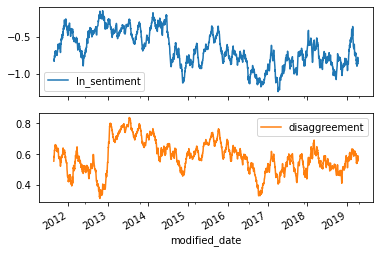

In [15]:
sentiment_day[["ln_sentiment","disaggreement"]].rolling(40).mean().plot(subplots = True)

In [16]:
trade_gx = pd.read_csv("300251_trade.csv",index_col = "Date",parse_dates = ["Date"])
trade_gx.head()

,High,Low,Open,Close,Volume,Adj Close
Date,,,,,,
2011-08-03,3.11688,2.91417,2.95038,3.08025,464007031.0,2.093177
2011-08-04,3.20388,3.00949,3.19098,3.02489,220479900.0,2.055557
2011-08-05,3.17516,2.87379,2.97161,3.14019,230343337.0,2.133909
2011-08-08,3.18598,2.92666,3.14269,3.08400,178499569.0,2.095725
2011-08-09,3.39244,3.03030,3.03863,3.31335,203363472.0,2.251579


<AxesSubplot:xlabel='Date'>

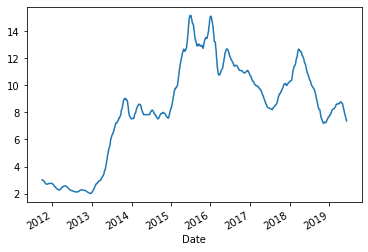

In [17]:
trade_gx.Close.rolling(40).mean().plot()

##  填充缺失值

由于某些天可能没有任何评论，那么对应的评论情绪就不存在，这不是特别合理，我们认为可以使用前一天的情绪数据填补。例如，我们查看sentiment_day[155:165]，我们发现2011-12-24没有任何评论

In [18]:
sentiment_day[155:165]

,ensemble_sentiment,positive,negative,ln_sentiment,comments_count,disaggreement
modified_date,,,,,,
2011-12-19,0,2,2,0.000000,4,1.000000
2011-12-20,-2,1,3,-0.693147,4,0.500000
2011-12-21,-1,1,2,-0.405465,3,0.666667
2011-12-22,-4,0,4,-1.609438,4,0.000000
2011-12-23,-2,0,2,-1.098612,2,0.000000
2011-12-25,1,1,0,0.693147,1,0.000000
2011-12-26,-4,0,4,-1.609438,4,0.000000
2011-12-27,-6,3,9,-0.916291,12,0.500000
2011-12-28,-4,1,5,-1.098612,6,0.333333


In [19]:
# 以天为单位重采样，如果有缺失的天，则会引入缺失值。
# 我们使用函数ffill()将前一天的数值填充到缺失值上。
sentiment_day = sentiment_day.resample("D").ffill()

In [20]:
sentiment_day[155:165]

,ensemble_sentiment,positive,negative,ln_sentiment,comments_count,disaggreement
modified_date,,,,,,
2011-12-17,-2,1,3,-0.693147,4,0.500000
2011-12-18,-2,1,3,-0.693147,4,0.500000
2011-12-19,0,2,2,0.000000,4,1.000000
2011-12-20,-2,1,3,-0.693147,4,0.500000
2011-12-21,-1,1,2,-0.405465,3,0.666667
2011-12-22,-4,0,4,-1.609438,4,0.000000
2011-12-23,-2,0,2,-1.098612,2,0.000000
2011-12-24,-2,0,2,-1.098612,2,0.000000
2011-12-25,1,1,0,0.693147,1,0.000000


## 生成情绪相关指标（移动均值、动量）

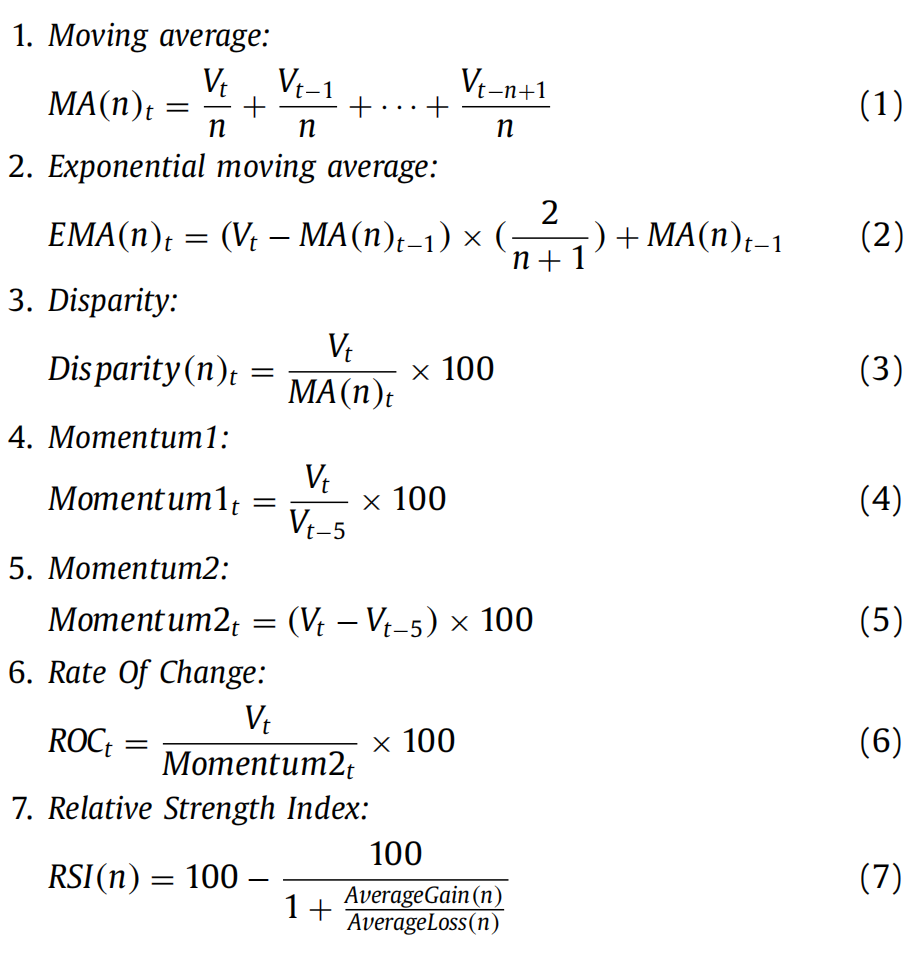

### 生成移动均值

In [21]:
for i in range(1,7):
    c = "ln_sentiment_moving_avg_{}".format(i)
    sentiment_day[c] = sentiment_day.ln_sentiment.rolling(i).mean().shift(1)
    
for i in range(1,7):
    c = "disaggreement_moving_avg_{}".format(i)
    sentiment_day[c] = sentiment_day.disaggreement.rolling(i).mean().shift(1)

In [ ]:
sentiment_day.head()

### 生成情感相关的动量指标

In [22]:
for i in range(1,7):
    c = "ln_sentiment_momentum_{}".format(i)
    sentiment_day[c] = (sentiment_day.ln_sentiment - sentiment_day.ln_sentiment.shift(i)).shift(1)

In [23]:
for i in range(1,7):
    c = "disaggreement_momentum_avg_{}".format(i)
    sentiment_day[c] = (sentiment_day.disaggreement - sentiment_day.disaggreement.shift(i)).shift(1)

In [24]:
sentiment_day.head()

,ensemble_sentiment,positive,negative,ln_sentiment,comments_count,disaggreement,ln_sentiment_moving_avg_1,ln_sentiment_moving_avg_2,ln_sentiment_moving_avg_3,ln_sentiment_moving_avg_4,...,ln_sentiment_momentum_3,ln_sentiment_momentum_4,ln_sentiment_momentum_5,ln_sentiment_momentum_6,disaggreement_momentum_avg_1,disaggreement_momentum_avg_2,disaggreement_momentum_avg_3,disaggreement_momentum_avg_4,disaggreement_momentum_avg_5,disaggreement_momentum_avg_6
modified_date,,,,,,,,,,,,,,,,,,,,,
2011-07-15,-4,2,6,-0.847298,8,0.5,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-16,1,1,0,0.693147,1,0.0,-0.847298,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-17,1,1,0,0.693147,1,0.0,0.693147,-0.077075,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.5,NaN,NaN,NaN,NaN,NaN
2011-07-18,0,1,1,0.000000,2,1.0,0.693147,0.693147,0.179666,NaN,...,NaN,NaN,NaN,NaN,0.0,-0.5,NaN,NaN,NaN,NaN
2011-07-19,-2,1,3,-0.693147,4,0.5,0.000000,0.346574,0.462098,0.134749,...,0.847298,NaN,NaN,NaN,1.0,1.0,0.5,NaN,NaN,NaN


In [25]:
sentiment_day.to_csv("preprocessed_300251_comments_sentiment_day.csv")

# 合并市场数据、百度指数与情感指数

除了股吧情感，我们还需要引入百度指数和市场数据。
* 百度指数代表人们对企业的注意力
* 通过市场数据我们可以计算收益率和涨跌信息

一个重点是学习合并不同来源的数据。

## 读取百度指数
大家是在买股票还是卖股票时更需要搜索网络数据。

<img src="../img/search.png" align='left' height="400" width="600"/>

In [26]:
# 读取百度指数（我们之前提前下载了百度“光线传媒”搜索指数）
import pandas as pd
baidu_index = pd.read_excel("baidu_guangxian.xlsx",index_col="Date",parse_dates = ["Date"])

In [27]:
# 累积1-6天的baidu_index移动均值
for i in range(1,7):
    c = "baidu_index_moving_avg_{}".format(i)
    baidu_index[c] = baidu_index.baidu_index.rolling(i).mean().shift(1)

In [28]:
for i in range(1,7):
    c = "baidu_index_momentum_{}".format(i)
    baidu_index[c] = (baidu_index.baidu_index - baidu_index.baidu_index.shift(i)).shift(1)

## 计算波动率、价格趋势指标

首先，读取上证综指(trade_sh)和光线传媒(trade)股价市场信息

In [29]:
trade_sh = pd.read_csv("000001_trade.csv",index_col= "Date",parse_dates = ["Date"])
trade_gx = pd.read_csv("300251_trade.csv",index_col = "Date",parse_dates = ["Date"])
trade_gx.head()

,High,Low,Open,Close,Volume,Adj Close
Date,,,,,,
2011-08-03,3.11688,2.91417,2.95038,3.08025,464007031.0,2.093177
2011-08-04,3.20388,3.00949,3.19098,3.02489,220479900.0,2.055557
2011-08-05,3.17516,2.87379,2.97161,3.14019,230343337.0,2.133909
2011-08-08,3.18598,2.92666,3.14269,3.08400,178499569.0,2.095725
2011-08-09,3.39244,3.03030,3.03863,3.31335,203363472.0,2.251579


In [ ]:
trade_gx.Close.pct_change()

In [30]:
trade_gx["close_pct_shift_1"] = trade_gx.Close.pct_change().shift(1)
trade_sh["close_pct_shift_1"] = trade_sh.Close.pct_change().shift(1)

In [31]:
# 累积trade_sh 1-6天的移动均值
for i in range(1,7):
    c = "market_sh_Close_moving_avg_{}".format(i)
    trade_sh[c] = trade_sh.Close.rolling(i).mean().shift(1)
    
for i in range(1,7):
    c = "market_sh_Close_momentum_{}".format(i)
    trade_sh[c] = (trade_sh.Close - trade_sh.Close.shift(i)).shift(1)

In [32]:
# 累积trade_gx 1-6天的移动均值
for i in range(1,7):
    c = "market_gx_Close_moving_avg_{}".format(i)
    trade_gx[c] = trade_gx.Close.rolling(i).mean().shift(1)
    
for i in range(1,7):
    c = "market_gx_Close_momentum_{}".format(i)
    trade_gx[c] = (trade_gx.Close - trade_gx.Close.shift(i)).shift(1)

然后，我们计算波动率和波动率的滞后1期的数值。怎么测量波动率呢？
用当天的最高股价和最低股价之差除以开盘价和收盘价的平均值来衡量日内**波动率**。

$$volatility = \frac {trade["High"]-trade["Low"]}{trade["Open"]+trade["Close"])/2}$$


参考文献：Das, S. R., & Chen, M. Y. (2007). Yahoo! for Amazon: Sentiment Extraction from Small Talk on the Web. Management Science, 53(9), 1375-1388.

In [33]:
trade_gx["volatility"] = (trade_gx["High"]-trade_gx["Low"])/(trade_gx["Open"]+trade_gx["Close"])/2
trade_sh["volatility"] = (trade_sh["High"]-trade_sh["Low"])/(trade_sh["Open"]+trade_sh["Close"])/2

In [34]:
# 累积 1-6天的移动均值
for i in range(1,7):
    c = "market_gx_volatility_moving_avg_{}".format(i)
    trade_gx[c] = trade_gx.volatility.rolling(i).mean().shift(1)
    
# 累积 1-6天的移动均值
for i in range(1,7):
    c = "market_sh_volatility_moving_avg_{}".format(i)
    trade_sh[c] = trade_sh.volatility.rolling(i).mean().shift(1)

生成收盘价的绝对变动数量

In [35]:
trade_gx["delta_close"] = trade_gx["Close"] - trade_gx['Close'].shift(1)
trade_sh["delta_close"] = trade_sh["Close"] - trade_sh['Close'].shift(1)

计算up_down，如果当天收盘价大于前一天收盘价，我们标记为涨=1，否则跌=0。

* 参考文献：Weng, B., Ahmed, M. A., & Megahed, F. M. (2017). Stock market one-day ahead movement prediction using disparate data sources. Expert Systems With Applications, 79(79), 153-163.

In [36]:
trade_gx["up_down"] = (trade_gx['delta_close']>0).astype("int")
trade_sh["up_down"] = (trade_sh['delta_close']>0).astype("int")
trade_gx.head()

,High,Low,Open,Close,Volume,Adj Close,close_pct_shift_1,market_gx_Close_moving_avg_1,market_gx_Close_moving_avg_2,market_gx_Close_moving_avg_3,...,market_gx_Close_momentum_6,volatility,market_gx_volatility_moving_avg_1,market_gx_volatility_moving_avg_2,market_gx_volatility_moving_avg_3,market_gx_volatility_moving_avg_4,market_gx_volatility_moving_avg_5,market_gx_volatility_moving_avg_6,delta_close,up_down
Date,,,,,,,,,,,,,,,,,,,,,
2011-08-03,3.11688,2.91417,2.95038,3.08025,464007031.0,2.093177,NaN,NaN,NaN,NaN,...,NaN,0.016807,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2011-08-04,3.20388,3.00949,3.19098,3.02489,220479900.0,2.055557,NaN,3.08025,NaN,NaN,...,NaN,0.015637,0.016807,NaN,NaN,NaN,NaN,NaN,-0.05536,0
2011-08-05,3.17516,2.87379,2.97161,3.14019,230343337.0,2.133909,-0.017973,3.02489,3.052570,NaN,...,NaN,0.024655,0.015637,0.016222,NaN,NaN,NaN,NaN,0.11530,1
2011-08-08,3.18598,2.92666,3.14269,3.08400,178499569.0,2.095725,0.038117,3.14019,3.082540,3.081777,...,NaN,0.020823,0.024655,0.020146,0.019033,NaN,NaN,NaN,-0.05619,0
2011-08-09,3.39244,3.03030,3.03863,3.31335,203363472.0,2.251579,-0.017894,3.08400,3.112095,3.083027,...,NaN,0.028506,0.020823,0.022739,0.020372,0.01948,NaN,NaN,0.22935,1


我们也尝试预测后续几天的收盘价波动，下面生成接下来5天的股价涨跌

In [37]:
for i in range(1,6):
    trade_gx["up_down_{}".format(i)] = trade_gx.up_down.shift(-i) # 注意：这里是负号

## 合并数据

In [38]:
# 首先读取上节课处理后的数据，即每天的情感数据集
sentiment_daily = pd.read_csv("preprocessed_300251_comments_sentiment_day.csv",
                      index_col="modified_date", 
                      parse_dates = ["modified_date"],
                       encoding = "gbk")
sentiment_daily.head()

,ensemble_sentiment,positive,negative,ln_sentiment,comments_count,disaggreement,ln_sentiment_moving_avg_1,ln_sentiment_moving_avg_2,ln_sentiment_moving_avg_3,ln_sentiment_moving_avg_4,...,ln_sentiment_momentum_3,ln_sentiment_momentum_4,ln_sentiment_momentum_5,ln_sentiment_momentum_6,disaggreement_momentum_avg_1,disaggreement_momentum_avg_2,disaggreement_momentum_avg_3,disaggreement_momentum_avg_4,disaggreement_momentum_avg_5,disaggreement_momentum_avg_6
modified_date,,,,,,,,,,,,,,,,,,,,,
2011-07-15,-4,2,6,-0.847298,8,0.5,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-16,1,1,0,0.693147,1,0.0,-0.847298,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-17,1,1,0,0.693147,1,0.0,0.693147,-0.077075,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.5,NaN,NaN,NaN,NaN,NaN
2011-07-18,0,1,1,0.000000,2,1.0,0.693147,0.693147,0.179666,NaN,...,NaN,NaN,NaN,NaN,0.0,-0.5,NaN,NaN,NaN,NaN
2011-07-19,-2,1,3,-0.693147,4,0.5,0.000000,0.346574,0.462098,0.134749,...,0.847298,NaN,NaN,NaN,1.0,1.0,0.5,NaN,NaN,NaN


我们使用[merge](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.merge.html)函数合并数据集。下面我们合并trade和trade_sh，由于这两个数据集有很多相同的变量，我们使用后缀想("_GX","_SH")，其中前者表示光纤传媒，后缀表示上证指数。

how : {‘left’, ‘right’, ‘outer’, ‘inner’}, default ‘inner’
* left: use only keys from left frame, similar to a SQL left outer join; preserve key order.
* right: use only keys from right frame, similar to a SQL right outer join; preserve key order.

In [39]:
trade_merged = pd.merge(left=trade_gx,
                        right=trade_sh,
                        left_index = True,
                        right_index = True,
                        suffixes = ("_GX","_SH"),
                        how="left")
trade_merged.columns

Index(['High_GX', 'Low_GX', 'Open_GX', 'Close_GX', 'Volume_GX', 'Adj Close_GX',
       'close_pct_shift_1_GX', 'market_gx_Close_moving_avg_1',
       'market_gx_Close_moving_avg_2', 'market_gx_Close_moving_avg_3',
       'market_gx_Close_moving_avg_4', 'market_gx_Close_moving_avg_5',
       'market_gx_Close_moving_avg_6', 'market_gx_Close_momentum_1',
       'market_gx_Close_momentum_2', 'market_gx_Close_momentum_3',
       'market_gx_Close_momentum_4', 'market_gx_Close_momentum_5',
       'market_gx_Close_momentum_6', 'volatility_GX',
       'market_gx_volatility_moving_avg_1',
       'market_gx_volatility_moving_avg_2',
       'market_gx_volatility_moving_avg_3',
       'market_gx_volatility_moving_avg_4',
       'market_gx_volatility_moving_avg_5',
       'market_gx_volatility_moving_avg_6', 'delta_close_GX', 'up_down_GX',
       'up_down_1', 'up_down_2', 'up_down_3', 'up_down_4', 'up_down_5',
       'High_SH', 'Low_SH', 'Open_SH', 'Close_SH', 'Volume_SH', 'Adj Close_SH',
       'cl

合并sentiment_daily和trade_merged

In [40]:
sentiment_trade_merged = pd.merge(left=trade_merged,
                        right=sentiment_daily,
                        left_index = True,
                        right_index = True,
                        how="left")

In [41]:
sentiment_trade_merged.columns

Index(['High_GX', 'Low_GX', 'Open_GX', 'Close_GX', 'Volume_GX', 'Adj Close_GX',
       'close_pct_shift_1_GX', 'market_gx_Close_moving_avg_1',
       'market_gx_Close_moving_avg_2', 'market_gx_Close_moving_avg_3',
       'market_gx_Close_moving_avg_4', 'market_gx_Close_moving_avg_5',
       'market_gx_Close_moving_avg_6', 'market_gx_Close_momentum_1',
       'market_gx_Close_momentum_2', 'market_gx_Close_momentum_3',
       'market_gx_Close_momentum_4', 'market_gx_Close_momentum_5',
       'market_gx_Close_momentum_6', 'volatility_GX',
       'market_gx_volatility_moving_avg_1',
       'market_gx_volatility_moving_avg_2',
       'market_gx_volatility_moving_avg_3',
       'market_gx_volatility_moving_avg_4',
       'market_gx_volatility_moving_avg_5',
       'market_gx_volatility_moving_avg_6', 'delta_close_GX', 'up_down_GX',
       'up_down_1', 'up_down_2', 'up_down_3', 'up_down_4', 'up_down_5',
       'High_SH', 'Low_SH', 'Open_SH', 'Close_SH', 'Volume_SH', 'Adj Close_SH',
       'cl

将百度指数合并在一起

In [42]:
sentiment_trade_baidu_merged = pd.merge(left=sentiment_trade_merged,
                        right=baidu_index,
                        left_index = True,
                        right_index = True,
                        how="left")

In [43]:
print(sentiment_trade_baidu_merged.shape)
cols = []
for c in sentiment_trade_baidu_merged.columns:
    cols.append(c)
cols

(1906, 104)


['High_GX',
 'Low_GX',
 'Open_GX',
 'Close_GX',
 'Volume_GX',
 'Adj Close_GX',
 'close_pct_shift_1_GX',
 'market_gx_Close_moving_avg_1',
 'market_gx_Close_moving_avg_2',
 'market_gx_Close_moving_avg_3',
 'market_gx_Close_moving_avg_4',
 'market_gx_Close_moving_avg_5',
 'market_gx_Close_moving_avg_6',
 'market_gx_Close_momentum_1',
 'market_gx_Close_momentum_2',
 'market_gx_Close_momentum_3',
 'market_gx_Close_momentum_4',
 'market_gx_Close_momentum_5',
 'market_gx_Close_momentum_6',
 'volatility_GX',
 'market_gx_volatility_moving_avg_1',
 'market_gx_volatility_moving_avg_2',
 'market_gx_volatility_moving_avg_3',
 'market_gx_volatility_moving_avg_4',
 'market_gx_volatility_moving_avg_5',
 'market_gx_volatility_moving_avg_6',
 'delta_close_GX',
 'up_down_GX',
 'up_down_1',
 'up_down_2',
 'up_down_3',
 'up_down_4',
 'up_down_5',
 'High_SH',
 'Low_SH',
 'Open_SH',
 'Close_SH',
 'Volume_SH',
 'Adj Close_SH',
 'close_pct_shift_1_SH',
 'market_sh_Close_moving_avg_1',
 'market_sh_Close_moving_

In [44]:
sentiment_trade_baidu_merged.to_csv("preprocessed_300251_comments_sentiment_trade_baidu.csv")

思考：<font color=red face=雅黑>提取合适的特征有助于提升市场涨跌预测的效果，根据您的经验或文献阅读，结合现有的数据，请生成一项新的特征，并尝试编程实现</font>

参考文献：Weng, B., Ahmed, M. A., & Megahed, F. M. (2017). Stock market one-day ahead movement prediction using disparate data sources. Expert Systems with Applications, 79, 153-163.

# 决策树与随机森林

为了应用上节课生成的多项特征预测股价的涨跌，我们拟使用决策树和随机森林模型。决策树会生成类似if-then的规则集合，主要优点是：模型的可解释性高，分类速度快。随机森林有其独特的优点：能够处理很高维度的数据，并且不用做特征选择，模型泛化能力强。

参考资料：
* 李航：统计学习方法，2012，北京.清华大学出版社.
* 周志华 著.机器学习,2016，北京:清华大学出版社.
* Aurélien Géron：Hands-on Machine Learning with Scikit-Learn, Keras, and TensorFlow. 2019,O’Reilly Media, Inc.

## decision tree

决策树由节点和变组成，节点有两种类型，内部节点（例如1、2、3、5、6）和叶子节点（例如4）。**内部节点**表示一个特征或属性，**叶子节点**表示一个类。我们用周志华（2016）的西瓜分类的示意图来展示决策树的形状：

<img src="../img/tree.png" align='left' height="400" width="500"/>

决策树是对于给定特征空间上的一个划分，树上每一条从根节点到叶节点的路径将特征空间划分成互不相交的一个区域。下图示例：决策树对应于条件概率分布。

<img src="../img/decision_tree.png" align='left' height="600" width="700"/>

构建决策树很重要的一步是要**选取分支特征**。

下面用一个贷款数据为例解释如何选择分类特征(李航 2012)。表中有15个训练样本，每个样本有4个特征：年龄（青年、中年、老年）、是否工作、是否有房子、信贷情况（一般、好、非常好）。训练样本类别标签有两类，分别是是否提供贷款。

<img src="../img/loan.png" align='left' height="700" width="800"/>

上面的特征有年龄、是否有工作、是否有自己的房子、信贷情况，例如我们可以选择年龄来划分、也可以选择是否有工作来划分，如下图所示。

这样的决策树可以有多种，但是哪一种是最好的呢? 一个好的决策树，**分类完成后在叶节点中的样本的类别相比全部训练样本应该更加纯**。比如在上边例子中，所有样本中类别为是和否的分布占比为60%和40%，如果我们用是否有工作来进行分类，那分类完成后，有工作的样本类别是和否分布占比为100%，0%，没工作的样本类别是和否分布占比为40%，60%。可以看出，用工作来进行样本的分类比原样本是有提升的。

<img src="../img/feature.png" align='left' height="300" width="400"/>

[Entropy](https://d2l.ai/chapter_appendix-mathematics-for-deep-learning/information-theory.html)

**Definition of Shannon entropy**

For any random variable $X$ that follows a probability distribution $P$ with a probability density function (p.d.f.) or a probability mass function (p.m.f.) $p(x)$, we measure the expected amount of information through *entropy* (or *Shannon entropy*)

$$H(X) = - E_{x \sim P} [\log p(x)].$$

To be specific, if $X$ is discrete, $$H(X) = - \sum_i p_i \log p_i \text{, where } p_i = P(X_i).$$

Otherwise, if $X$ is continuous, we also refer entropy as *differential entropy*

$$H(X) = - \int_x p(x) \log p(x) \; dx.$$

For example, imagine that a slot machine system emits statistical independently symbols ${s_1, \ldots, s_k}$ with probabilities ${p_1, \ldots, p_k}$ respectively. Then the entropy of this system equals to the average self-information from observing each output, i.e.,

$$H(S) = \sum_i {p_i \cdot I(s_i)} = - \sum_i {p_i \cdot \log p_i}.$$


下边举例说明。假设随机变量只有两个取值$x_1$和$x_2$，则其概率分布的取值为$p$和$1-p$，此时的熵为$$H(p) = -plog_2p-(1-p)log_2(1-p)$$

**熵越大时，则表明随机变量的混乱度越高**

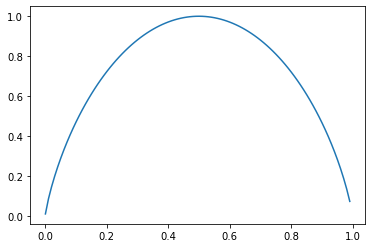

In [45]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(0.001,1,0.01)
y = -x*np.log2(x) - (1-x)* np.log2(1-x)
plt.plot(x,y)

直观上，如果一个特征具有更好的分类能力，或者说，按照这一特征将训练数据集分割成子集，使得各个子集在当前条件下有最好的分类，那么就更应该选择这个特征。**信息增益**就能够很好地表示这一直观的准则。

什么是信息增益呢？在划分数据集之前与之后**信息发生的变化成为信息增益**，知道如何计算信息增益，我们就可以计算每个特征值划分数据集获得的信息增益，获得信息增益最高的特征就是最好的选择。**可以把熵理解为：如果你从集合中随机抽取一个元素并猜测其结果，那么其结果的不确定性是多少？**

设有随机变量$(X,Y)$,其联合概率分布为：$$P(X = x_i, Y = y_j) = p_{ij}, i = 1,2,...,n; j = 1,2,...,m$$

**条件熵$H(Y|X)$表示在已知随机变量$X$的条件下随机变量Y的不确定性**，条件熵的表示如下：$$H(Y|X) = \sum_{i=1}^n p_iH(Y|X = x_i) $$
这里$p_i = P(X = x_i), i = 1,2,...,n$

**当熵和条件熵的概率有数据估计得到时，所对应的熵称为经验熵，对应的条件熵称为经验条件熵**。什么叫由数据估计？比如有10个数据，一共有两个类别，A类和B类。其中有7个数据属于A类，则该A类的概率可以估计为十分之七。其中有3个数据属于B类，则该B类的概率即为十分之三。浅显的解释就是，这概率是我们根据数据数出来的。

>信息增益表示得知特征$X$的信息而使得$Y$的信息的不确定性减少的程度。下面定义特征$A$对训练数据集$D$的信息增益$g(D,A)$,定义**集合D的经验熵为$H(D)$与特征A给定条件下D的经验条件熵为$H(D|A)$之差**，$$g(D,A) = H(D) - H(D|A)$$

一般而言，我们也称熵与条件熵之差为互信息。因此信息增益等价于训练数据集中雷雨特征的互信息。

我们定义贷款申请样本数据表中的数据为训练数据集D，则训练数据集D的经验熵为$H(D)$，$|D|$表示其样本容量，及样本个数。设有$K$个类$C_k$，$k = 1,2,3,...,K$，$|Ck|$为属于类$C_k$的样本个数，这经验熵公式可以写为：$$H(D) = -\sum_{k=1}^K \frac {|C_k|}{|D|}log_2\frac {|C_k|}{|D|}$$
在我们的样本$D$中有6个不贷款，9个贷款，那么经验熵$$H(D) = -\frac {9}{15} log_2\frac {9}{15} - \frac {6}{15} log_2\frac {6}{15} = 0.971$$

特征$A$将$D$分为$n$个子集，每个子集的样本个数是$D_i$,那么特征$A$对数据集$D$的经验条件熵$H(D|A)$:$$H(D|A) = -\sum_{i = 1}^n\frac {|D_i|}{|D|}\sum_{k=1}^K \frac {|D_{ik}|}{|D_i|}log_2\frac {|D_{ik}|}{|D_i|}$$
计算了$H(D)$和$H(D|A)$，我们就可以得到$g(D,A) = H(D) - H(D|A)$

如果我们用$A_1,A_2,A_3,A_4$分别表示年龄、工作、有自己房子、信贷情况4个特征。这里我们用$A_1$（年龄）来做例子，计算用特征年龄后的信息增益，用年龄可以将人群分为青年、中年、老年，每个子人群($D_i$)都是5个，$$g(D,A_1) = H(D) - [\frac {5}{15}H(D_1) + \frac {5}{15}H(D_2) + \frac {5}{15}H(D_3)] \\ = 0.975 - [\frac {5}{15} (-\frac {2}{5}log_2\frac {2}{5} - \frac {3}{5}log_2\frac {3}{5})] - [\frac {5}{15} (-\frac {3}{5}log_2\frac {3}{5} - \frac {2}{5}log_2\frac {2}{5})] - [\frac {5}{15} (-\frac {4}{5}log_\frac {4}{5} - \frac {1}{5}log_2\frac {1}{5})] \\ = 0.971- 0.888 = 0.083$$ 

按照相似的逻辑，我们可以计算出$g(D,A_2) = 0.324, g(D,A_3) = 0.420$



思考题：<font color=red face=雅黑>在本节课的信贷决策树构建过程中,我们已经计算出$A_1，A_2，A_3$特征对样本的信息增益，请您接下来**计算特征$A_4$（信贷情况）对样本的信息增益**，并从$A_1,A_2,A_3,A_4$选取信息增益最大的特征作为最优特征来分支？</font>

**ID3算法的核心是在决策树的各个节点上利用信息增益来选取特征，递归构建决策树**。

具体方法为：从根节点开始，对其包含的所有样本的所有特征计算信息增益，选取增益最大的特征作为节点特征（这样我们可以构建较浅的树），建立子节点，再对子节点递归进行以上操作，**直到**没有再能够分类的特征，或分类后信息增益小于某个阈值,或者数据集中所有实例都具有相同的类别标签，停止递归构建树。

这里要强调一下**叶子节点的分类输出**：叶子节点样本中数目最多的样本对应的类$C_k$作为该节点的类标签。

上面的计算说明，有无房子这个特征的信息增益是最大的，因此首先利用这个特征来构建树的根节点，将样本分为两个子集$D_1（A_3取值为是）,D_2（A_3取值为否）$
* $D_1$中所有样本类别均为是，因此不必再对$D_1$继续分类。
* 接着针对$D_2$需要从$A_1、A_2、A_4$中选择特征，我们发现$g(D,A_4)$最大，因此我们选择**是否有工作**作为最优的分支特征。分类完成后，有工作的样本类别都标记为"是"，没工作的样本类别都标记为"否"。样本不必再分类了。

<img src="../img/id3.png" align='left' height="300" width="300"/>

回归树：预测连续目标的任务称为回归任务，回归树叶子节点的输出是训练集中该节点的实例目标特征值的平均值。因此，我们可以使用方差作为对纯度的度量。

## random forest

集成学习（ensemble learning）通过构建并结合多个学习器来完成学习任务，有时也被称为多分类器系统。有两种创建组合的标准方法：提升法（boosting）和带装法（bagging）。这里我们介绍bagging（袋装法）。Bagging（bootstrap aggregating）采用的是**随机有放回的选择训练数据**构造分类器，最后组合。如下图所示：

<img src="../img/bagging.png" align='left' height="500" width="600"/>

采用有放回的抽样的主要目的是，使得采样样本每次都不同，因此训练出来的模型也是不同的。

决策树算法特别适合袋装法，因为决策树对数据集的改变非常敏感，数据集的微小改变可能导致算法选择不同的特征来生成节点。

随机森林是bagging中的一种方法。随机森林构造很多颗决策树，形成一个森林，然后用这些决策树共同决策输出类别是什么。在随机森林算法的过程中，有**两个随机的操作**：
* 特征选取随机选择：每棵决策树所需的特征是从整体的特征集中随机选取的。这也成为子空间采样。
* 输入数据随机选择：从全部训练样本（样本数为N）中选取一个可能有重复的大小同样为N的数据集进行训练（即bootstrap取样）。 


袋装法、**子空间采样**和决策树的结合，形成了随机森林。

<img src="../img/rf.jfif" align='left' height="400" width="500"/>

随机森林算法具体实现过程：
* A: 随机且有放回地从训练集中的抽取N个训练样本。
* B: 选取输入的训练数据后，构建决策树（方法：每一个分裂节点从整体的特征集M中选取m个特征构建，一般情况下m远小于M，通常是log_2(M)或者sqrt(M)），从这m个属性中根据某种策略（如信息增益）确定分支属性。
* C: 重复B步骤，直到不能分裂或达到我们设定的阈值（如叶子结点树或的树的深度），此时建立了一个决策树

**重复上面的A,B,C步骤，直到达到预定数目的树**。

随机森林中每个决策树被训练出来后，如何做组合策略呢？
* 可以使用投票方式，投票多的分类作为最终的分类。
* 对于连续目标的回归任务，鼓励使用中位数，而不是平均值，因为相对平均值受离群点的影响更大。

# 应用随机森林提前一天预测价格涨跌

前期我们准备了大量的特征数据，同时也学习了决策树和随机森林，这个小节我们将:
* 构建决策树和随机森林模型
* 并引入AUC模型评价指标，验证股评情感指数是否能够有效地提高市场预测效果

参考资料：Aurélien Géron：Hands-on Machine Learning with Scikit-Learn, Keras, and TensorFlow. 2019,O’Reilly Media, Inc.

## 准备数据

In [ ]:
#  选择X的列和y的列
import pandas as pd
def load_data_set(X_columns,Y_colum):
    sentiment_trade_baidu = pd.read_csv("preprocessed_300251_comments_sentiment_trade_baidu.csv",
                                    index_col ="Date",
                                    parse_dates =["Date"])
    st = sentiment_trade_baidu.copy()
    st.dropna(axis = 0,inplace = True)
    X = st[X_columns].copy()
    y = st[Y_colum].copy()
    y = y[Y_colum]
    return X,y

In [ ]:
"""removed = ['High_GX',
 'Low_GX',
 'Open_GX',
 'Close_GX',
 'Volume_GX',
 'Adj Close_GX',
 'volatility_GX',
 'delta_close_GX',
 'up_down_GX',
 'High_SH',
 'Low_SH',
 'Open_SH',
 'Close_SH',
 'Volume_SH',
 'Adj Close_SH',
 'volatility_SH',
 'delta_close_SH',
 'up_down_SH',   
'ensemble_sentiment',
 'positive',
 'negative',
 'ln_sentiment',
 'comments_count',
 'disaggreement',
'baidu_index',]

for c in removed:
    cols.remove(c)"""

In [ ]:
#  选择X的列和y的列
columns_sentiment = ['ln_sentiment_moving_avg_1',
 'ln_sentiment_moving_avg_2',
 'ln_sentiment_moving_avg_3',
 'ln_sentiment_moving_avg_4',
 'ln_sentiment_moving_avg_5',
 'ln_sentiment_moving_avg_6',
 'disaggreement_moving_avg_1',
 'disaggreement_moving_avg_2',
 'disaggreement_moving_avg_3',
 'disaggreement_moving_avg_4',
 'disaggreement_moving_avg_5',
 'disaggreement_moving_avg_6',
 'ln_sentiment_momentum_1',
 'ln_sentiment_momentum_2',
 'ln_sentiment_momentum_3',
 'ln_sentiment_momentum_4',
 'ln_sentiment_momentum_5',
 'ln_sentiment_momentum_6',
 'disaggreement_momentum_avg_1',
 'disaggreement_momentum_avg_2',
 'disaggreement_momentum_avg_3',
 'disaggreement_momentum_avg_4',
 'disaggreement_momentum_avg_5',
 'disaggreement_momentum_avg_6']

In [ ]:
columns_market = ['market_gx_Close_moving_avg_1',
 'market_gx_Close_moving_avg_2',
 'market_gx_Close_moving_avg_3',
 'market_gx_Close_moving_avg_4',
 'market_gx_Close_moving_avg_5',
 'market_gx_Close_moving_avg_6',
 'market_gx_Close_momentum_1',
 'market_gx_Close_momentum_2',
 'market_gx_Close_momentum_3',
 'market_gx_Close_momentum_4',
 'market_gx_Close_momentum_5',
 'market_gx_Close_momentum_6',
 'market_gx_volatility_moving_avg_1',
 'market_gx_volatility_moving_avg_2',
 'market_gx_volatility_moving_avg_3',
 'market_gx_volatility_moving_avg_4',
 'market_gx_volatility_moving_avg_5',
 'market_gx_volatility_moving_avg_6',
 'close_pct_shift_1_GX',
 'market_sh_Close_moving_avg_1',
 'market_sh_Close_moving_avg_2',
 'market_sh_Close_moving_avg_3',
 'market_sh_Close_moving_avg_4',
 'market_sh_Close_moving_avg_5',
 'market_sh_Close_moving_avg_6',
 'market_sh_Close_momentum_1',
 'market_sh_Close_momentum_2',
 'market_sh_Close_momentum_3',
 'market_sh_Close_momentum_4',
 'market_sh_Close_momentum_5',
 'market_sh_Close_momentum_6',
 'market_sh_volatility_moving_avg_1',
 'market_sh_volatility_moving_avg_2',
 'market_sh_volatility_moving_avg_3',
 'market_sh_volatility_moving_avg_4',
 'market_sh_volatility_moving_avg_5',
 'market_sh_volatility_moving_avg_6',
 'close_pct_shift_1_SH']

columns_baidu = ['baidu_index_moving_avg_1',
 'baidu_index_moving_avg_2',
 'baidu_index_moving_avg_3',
 'baidu_index_moving_avg_4',
 'baidu_index_moving_avg_5',
 'baidu_index_moving_avg_6',
 'baidu_index_momentum_1',
 'baidu_index_momentum_2',
 'baidu_index_momentum_3',
 'baidu_index_momentum_4',
 'baidu_index_momentum_5',
 'baidu_index_momentum_6']

In [ ]:
Y_colum = ["up_down_1"]  # 这里我们预测下一天的股价涨跌

In [ ]:
X_columns = columns_baidu + columns_market + columns_sentiment

In [ ]:
# 获取数据集
# 训练集(我们用前1500个样本做训练）中上涨占比
X,y = load_data_set(X_columns,Y_colum)
up = (y[:]==1).sum()
up/len(y[:])

In [ ]:
# 测试集样本个数
len(y[1500:])

In [ ]:
# 测试集中上涨的个数
up

## plot_confusion_matrix

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

def plot_confusion_matrix(y_test, y_pred,xticklabels=[-1,1],yticklabels = [-1,1]):
    """
    可视化混淆矩阵
    参数：
        y_test：真实的测试标签数据
        y_pred：预测的标签数据
        xticklabels = [-1,1],-1表示下跌，1表示上涨，yticklabels的含义类似
    返回：
        可视化混淆矩阵，并返回accuracy_score
    """
    sns.set()
    mat = confusion_matrix(y_test, y_pred)
    sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
                xticklabels=xticklabels, yticklabels = yticklabels)
    plt.xlabel('true label')
    plt.ylabel('predicted label')
    print("accuracy_score: ",accuracy_score(y_test,y_pred))

## train and test decision tree model

准备数据

In [ ]:
X_columns = columns_baidu + columns_market + columns_sentiment
X,y = load_data_set(X_columns,Y_colum)

训练并测试模型

In [ ]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier()
# 输入数据X[:1500], y[:1500]
clf.fit(X[:1500], y[:1500].values.ravel())

In [ ]:
#使用测试数据做预测
y_pred = clf.predict(X[1500:])
# 画出confusion_matrix
plot_confusion_matrix(y_test=y[1500:], y_pred=y_pred)

## train and test random forest model

准备数据

In [ ]:
X_columns = columns_baidu + columns_market + columns_sentiment
X,y = load_data_set(X_columns,Y_colum)

In [ ]:
import numpy as np
a = np.arange(16).reshape(4,4)
a.ravel()

我们可以通过[GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)寻找合适的参数，寻找最优参数需要较高的运算。

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from sklearn.model_selection import GridSearchCV
parameters = {'n_estimators':[50,70,90,100], 'max_depth':[5, 10,15]}
rf = RandomForestClassifier()
clf = GridSearchCV(rf, parameters)
clf.fit(X[:1500], y[:1500].values.ravel())

In [ ]:
clf.best_params_

下面结果显示随机森林效果比决策树效果好，后续我们分析使用随机森林模型

In [ ]:
clf = RandomForestClassifier(n_estimators=100, max_depth=10)
# 输入数据X[:1500], y[:1500]
clf.fit(X[:1500], y[:1500].values.ravel())
#使用测试数据做预测
y_pred = clf.predict(X[1500:])
# 画出confusion_matrix
plot_confusion_matrix(y_test=y[1500:], y_pred=y_pred)

## 比较不同特征训练模型的AUC

### AUC
对于二分类问题，我们可以根据其真实类别与模型预测类别的组合划分为真正例（true positive）（例如负面口碑、违约贷款）、真反例(true negative)、假正例（false postive）、假反例（false negative）四种情形（李航 2012）。分类的混淆矩阵如下表所示：
<table border="1">
<tr>
<td></td>
<td>正例（预测结果）</td>
<td>反例（预测结果）</td>
</tr>
<tr>
<td>正例（真实情况）</td>
<td>TP（true positive）</td>
<td>FN（false negative）</td>
</tr>
<tr>
<td>反例（真实情况）</td>
<td>FP（false positive）</td>
<td>TN（true negative）</td>
</tr>
</table>

这里我们再介绍一种模型度量指标AUC（Area Under Curve）被定义为ROC曲线下与坐标轴围成的面积，这种指标在非平衡样本中（例如正样本比例很小）是优秀的度量指标。在弄清楚AUC，我们要了解什么是ROC曲线,参考[An introduction to ROC analysis](https://ccrma.stanford.edu/workshops/mir2009/references/ROCintro.pdf)，这里介绍两个概念True postive rate和False positive rate。

Recall也称为**True postive rate**。$$tp\_rate = \frac {Positives\ correctly\ classified}{Total\ positives}$$
**False positive rate** 也称为(false alarm rate) $$fp\_rate = \frac {Negatives\ incorrectly\ classified}{Total\ negatives}$$

ROC图是二维图，其中tp rate绘制在Y轴上，fp rate绘制在X轴上。**ROC图描述了收益(真阳性)和成本(假阳性)之间的相对权衡**。下图是5个分类器的ROC图。

这里有一个权衡:召回率(TPR)越高，分类器产生的假阳性(FPR)就越多。

ROC中的一个点代表一个分类器，每个分类器产生一个(fp rate，tp rate)对，对应于ROC空间中的一个点。我们可以通过调整**threshold**（例如预测的概率阈值）来生成不同的分类器。这里$(0,0)$和$(1,1)$点代表什么意思呢？
- (0,0)点表示阈值非常高，所有的都没检测出来。
- (1,1)表示阈值非常低，所有的正样本都检测出来，但是所有的负样本也检查错误了。

<img src="../img/ROC.png" align='left' height="300" width="300"/>

ROC曲线**对角线y = x表示随机猜测的策略**。例如，如果一个分类器在一半的时间里随机猜测是正类，它可以正确猜中正例和负例中的一半，这将在ROC空间中产生点(0.5,0.5)。如果90%的时间猜测正类别，则可以猜中90%的正例，但是假阳性率也会增加到90%(把90%的负例也猜成正例了），在ROC空间中产生(0.9,0.9)。

好的分类器会尽可能地远离对角线(一般是朝向左上角)。比较分类器的一种方法是测量曲线下的面积(AUC)。一个完美的分类器的AUC等于1。

<img src="../img/AUC.png" align='left' height="300" width="300"/>

In [ ]:
def plot_roc_curve(fpr,tpr,label = None):
    """
    plot the roc curve
    """
    plt.plot(fpr,tpr,linewidth=2,label = label)
    plt.plot([0,1],[0,1],"k--")

### AUC with stock market data

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

clf = RandomForestClassifier(n_estimators=200, max_depth=10)
X_columns = columns_market
X,y = load_data_set(X_columns,Y_colum)

# 输入数据X[:1500], y[:1500]
clf.fit(X[:1500], y[:1500].values.ravel())

In [ ]:
#使用测试数据做预测
y_pred = clf.predict(X[1500:])
y_scores = clf.predict_proba(X[1500:]) # 预测上涨和下跌的概率
y_scores = y_scores[:,1] # 属于正例（1）的概率
fpr_trade, tpr_trade, thresholds = roc_curve(y[1500:], y_scores)
print("AUC:",roc_auc_score(y[1500:], y_scores))
plot_roc_curve(fpr_trade,tpr_trade)

In [ ]:
plot_confusion_matrix(y_test=y[1500:], y_pred=y_pred)

### AUC with market data and Baidu index

In [ ]:
X_columns = columns_baidu + columns_market
X,y = load_data_set(X_columns,Y_colum)
# 输入数据X[:1500], y[:1500]
clf.fit(X[:1500], y[:1500].values.ravel())
#使用测试数据做预测
y_pred = clf.predict(X[1500:])

y_scores = clf.predict_proba(X[1500:]) # 预测上涨和下跌的概率
y_scores = y_scores[:,1] # 属于正例（1）的概率
fpr_trade_baidu, tpr_trade_baidu, thresholds = roc_curve(y[1500:], y_scores)
print("AUC: ",roc_auc_score(y[1500:], y_scores))
plot_roc_curve(fpr_trade_baidu,tpr_trade_baidu)
#print("AUC: ",roc_auc_score(y[1500:], abs(y_scores-1)))

In [ ]:
plot_confusion_matrix(y_test=y[1500:], y_pred=y_pred)

### AUC with market, online review sentiments and Baidu index

In [ ]:
X_columns = columns_baidu + columns_market + columns_sentiment
X,y = load_data_set(X_columns,Y_colum)
# 输入数据X[:1500], y[:1500]
clf.fit(X[:1500], y[:1500].values.ravel())
#使用测试数据做预测
y_pred = clf.predict(X[1500:])

y_scores = clf.predict_proba(X[1500:]) # 预测上涨和下跌的概率
y_scores = y_scores[:,1] # 属于正例（1）的概率
fpr_full, tpr_full, thresholds = roc_curve(y[1500:], y_scores)
print("AUC: ",roc_auc_score(y[1500:], y_scores))
plot_roc_curve(fpr_full,tpr_full)

In [ ]:
plot_confusion_matrix(y_test=y[1500:], y_pred=y_pred)

In [ ]:
import numpy as np
x = np.array([3,0,2,5,1])
np.argsort(x)[::-1]

https://blog.csdn.net/qq_31307013/article/details/80454190

In [ ]:
importance = clf.feature_importances_

In [ ]:
import numpy as np
indces = np.argsort(importance)[::-1]
indces

In [ ]:
for i in indces:
    print(importance[i], "\t", X_columns[i])

### 比较不同数据集训练模型对应的AUC

In [ ]:
plt.plot(fpr_full,tpr_full,linewidth = 2, label = "sentiment+baidu_index+trade")
plt.plot(fpr_trade_baidu,tpr_trade_baidu,linewidth = 2, label = "baidu_index+trade")
plt.plot(fpr_trade,tpr_trade,linewidth = 2, label = "trade")
plt.plot([0,1],[0,1],"k--")
plt.axis([0,1,0,1])
plt.legend()
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")

思考：<font color=red face=雅黑>请使用随机森林模型预测第三天、第五天的涨跌，看看效果如何。y 可以取如下值：'up_down-2','up_down-4'，即Y_colum = ['up_down-2'] </font>

# 个人项目

## 个人项目基本要求

提交时间：
- 2022年7月1日之前

如何提交：发送压缩ZIP包到邮箱：342497883@qq.com，用“学号+姓名+final project”命名，压缩包内包括：
- 数据
- 代码
- 报告：封面、题目、摘要、关键词、引言、文献综述、研究方法、分析结果、结论、课程学习总结、附录、参考文献
- 重点参考文献

这里特别提示一下：课程学习总结(放到报告的最后一节）
- 课程平时学习过程遇到的挑战、如何解决的
- 课程项目中最困难的，最意想不到的地方，如何解决的
- 这门课的收获，以及给未来修读这门课程的同学的建议

代码要求
- 运行不要报错
- 要添加注释，鼓励使用jupyter的markdown做更多解释
- 如果抓取数据过多，可以提供一个抓取数据的测试代码，同时提供所有已经抓取好的数据
- 如果没有自己写代码抓取数据，则不需要提供数据抓取的代码

提示：代码中涉及文件地址请使用相对路径

成绩组成：
- 平时参与（10%）
- 平时作业（40%）
- 期中测试（10%）
- 个人项目（40%）：代码（数据获取、清理、分析的难度与工作量、代码的可读性）比重是70%，报告写作质量是30%。

报告写作要注意规范：我分享的典型的Managment Science期刊论文可以作为论文结构的参考。特别鼓励把研究方法和实证环节分开。

## 下周鼓励将课程报告初稿带到课堂交流
- 鼓励打印下来方便下周当面交流

# 课后练习题
- 如何基于上述的预测模型制定投资策略
- 编程实现

- 下周邀请同学分享